In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
import jax.numpy as jnp
import jax
from scipy.special import erfc, erfcinv
from functools import partial, wraps

from lib import neurons, input_gen, driver, utils

In [6]:
ns=200
nd=300
n = 10
rng = jax.random.PRNGKey(12345)

beta=5.75911
b = 2.55
bk =  4.0

hyper = neurons.HyperConfig1(nd=nd, ns=ns, n=n, b=b, bk=bk, beta=beta)
hyperD = neurons.HyperDynConfig1(b=b, bk=bk, beta=beta)
# neuron = neurons.Neuron_Decay_NonInt(hyperparameters=hyper)
neuron = neurons.Neuron_Decay_Int(hyperparameters=hyper)
# neuron = neurons.Neuron_Decay_Int_Variable_n_min1(hyperparameters=hyper)

nSamples = 3000
nUpdate_list = np.zeros((7, nSamples)) # n_tested_patterns=1000
rng, subkey = jax.random.split(rng)
for i, coeff in enumerate([1, 2, 4, 8 ,16, 32, 64]):
    print(f"Running for coeff={coeff}")
    if coeff == "infty":
        xs_gen = input_gen.Normal(nd, ns)
    else: 
        xs_gen = input_gen.Normal_Corr_across_Dendrites(nd=nd, ns=ns, coeff=coeff, key=subkey)
    rng, subkey = jax.random.split(rng)
    my_driver = driver.Driver1_nUpdated_record(neuron, xs_gen, subkey, hyperD, initial_state=None,resample_every=1000, n_tested_patterns=1000)
    my_driver.run(
            n_init_steps=10000,
            n_steps_phase1=3000,
            n_steps_phase2=00,
            n_steps_phase3=00,
            test_every_phase3=50,
            bs=jnp.array([b])
        )
    nUpdate_list[i, :] = my_driver.transient_record[:nSamples]

Running for coeff=1
Running for coeff=2
Running for coeff=4
Running for coeff=8
Running for coeff=16
Running for coeff=32
Running for coeff=64


In [ ]:
# np.save("../data/fixed_params/nUpdated_vs_coeff/int_params3.npy", nUpdate_list)

In [12]:
nUpdated_nonInt = np.load("../data/fixed_params/nUpdated_vs_coeff/nonInt_params3.npy")
nUpdated_variable_n_min1_int = np.load("../data/fixed_params/nUpdated_vs_coeff/int_variableN_min1_params3.npy")
nUpdated_int = np.load("../data/fixed_params/nUpdated_vs_coeff/int_params3.npy")

In [13]:
nUpdated_nonInt_var = np.var(nUpdated_nonInt, axis=1)
nUpdated_variable_n_min1_int_var = np.var(nUpdated_variable_n_min1_int, axis=1)
nUpdated_int_var = np.var(nUpdated_int, axis=1)

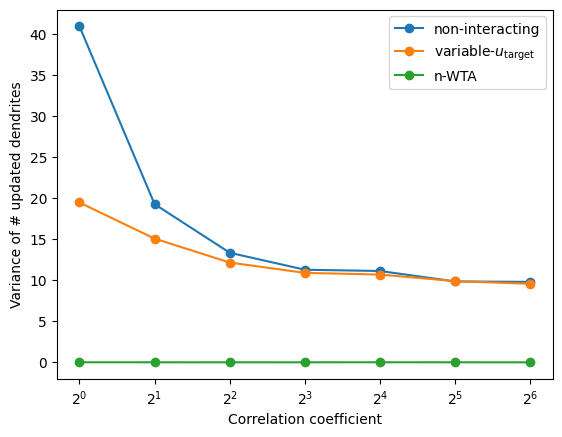

In [ ]:
coeff_list = np.array([1, 2, 4, 8, 16, 32, 64])
plt.plot(coeff_list, nUpdated_nonInt_var, marker='o', label='non-interacting')
plt.plot(coeff_list, nUpdated_variable_n_min1_int_var, marker='o', label=r'variable-$u_{\text{target}}$')
plt.plot(coeff_list, nUpdated_int_var, marker='o', label='n-WTA')

plt.xscale('log', base=2)
# plt.yscale('log')
# plt.yticks([1, 2, 4, 10, 20, 40], labels=['1', '2', '4', '10', '20', '40'])
plt.xlabel('Correlation coefficient')
plt.ylabel('Variance of # updated dendrites')
plt.legend()

# plt.savefig("../figures/nUpdated_var_vs_coeff_params3.png")
plt.show()

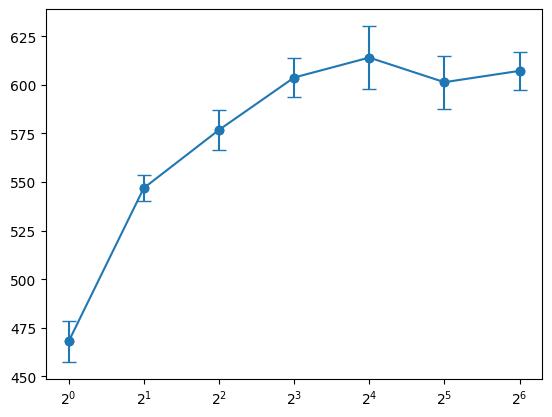

In [20]:
plt.plot(np.array([1, 2, 4, 8, 16, 32, 64]), np.mean(capa_list, axis=1), marker='o')
plt.errorbar(np.array([1, 2, 4, 8, 16, 32, 64]), np.mean(capa_list, axis=1), yerr=np.std(capa_list, axis=1), fmt='o', capsize=5, linestyle='None', color='C0')
plt.xscale('log', base=2)